# Triple-well: metastable BSO spectrum via neural-operator Galerkin projection

The system is the reflected 2D diffusion
$dX_t=-\nabla V(X_t)\,dt+1.09\,dW_t$ on
$\Omega=[-2,2]\times[-1,2]$, with wells near $(-1,0)$, $(1,0)$ and
$(0,\tfrac{5}{3})$. Its backward generator is
$\mathcal Lf=-\nabla V\cdot\nabla f+D\Delta f$, where
$D=1.09^2/2$. A Fourier neural operator learns
the finite-horizon KBE solution map $U_\tau f = \mathbb{E}[f(X_\tau)\,|\,X_0=\cdot]$
from sample pairs; a dictionary of 49 functions (constant + 48 learned) is
then refined jointly with the operator using the invariance loss. The final
BSO matrix $K$ is obtained from the frozen Phase-A operator over $3\tau$,
using reversible symmetrization and EDMD least squares on the dictionary.

**Finite-difference (FD) reference.** The red-circle reference is computed
without a learned model. The backward generator $\mathcal L$ is discretized
on an independent $128\times128$ uniform grid: centered second-order
differences are used for diffusion, first-order upwind differences for the
drift, and homogeneous Neumann conditions enforce reflection at every
boundary. This produces a sparse matrix $L_h$. ARPACK then extracts the six
eigenvalues of $L_h$ with largest real part, including the stationary
eigenvalue $\lambda_0=0$. For the finite-time eigenvalue plot they are mapped
to the common BSO horizon by
$\mu_j^{\mathrm{FD}}=\exp(\lambda_j^{\mathrm{FD}}T_{\mathrm{eff}})$ with
$T_{\mathrm{eff}}=3\tau=0.9$. Generator-eigenvalue
errors are evaluated by one-to-one Hungarian matching against the learned
BSO modes.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from plotting_utils import (
    PUBLICATION_STYLE, apply_physical_layout, apply_publication_rcparams,
    print_figure_caption, save_figure_pair, style_axis, y_from_top,
)
from project_paths import FIGURES_DIR, RESULTS_DIR as PROJECT_RESULTS_DIR

from kbe_observation_data import generate_kbe_dataset, compute_triple_well_fd_reference_lambdas
from edmd_bso_method import run_bso_pipeline
from experiments.triple_well.exp_triple_well import build_config

SOLVER_FILE = "solver_edmd.py"     # dictionary-training solver
OPERATOR = "fno"                   # operator backend: "fno"|"sfno"|"pino"|"deeponet"|"kernel"
QUICK = False                      # True = fast smoke run (minutes, low accuracy)
SEED = 2026
CKPT_DIR = None if QUICK else PROJECT_RESULTS_DIR / 'triple_well'   # QUICK runs are not cached

# Every layout value is explicit and measured at final paper size.
TW_SINGLE_FIGURE = {
    "figsize": (3.4, 3.4), "nrows": 1, "ncols": 1,
    "left_in": 0.55, "right_in": 0.12, "bottom_in": 0.47, "top_in": 0.28,
    "column_gap_in": 0.0, "row_gap_in": 0.0, "legend_ncol": 1,
}
TW_GRID_FIGURE = {
    "figsize": (7.0, 2.6), "nrows": 1, "ncols": 3,
    "left_in": 0.55, "right_in": 0.32, "bottom_in": 0.43, "top_in": 0.48,
    "column_gap_in": 0.65, "row_gap_in": 0.0,
    "suptitle_top_in": 0.05, "colorbar_size_percent": "4.5%",
    "colorbar_pad_in": 0.04,
}
apply_publication_rcparams()
STYLE = PUBLICATION_STYLE

In [ ]:
dataset = generate_kbe_dataset(
    "triple_well", n_samples=32 if QUICK else 64, seed=SEED,
    cache_path=None if CKPT_DIR is None else str(CKPT_DIR / 'dataset.pkl'),
    **(dict(N=48) if QUICK else {}))

A full run creates reusable runtime artifacts in `results/triple_well/`:

- `dataset.pkl` -- the generated KBE sample pairs;
- `fno.pt` -- the trained neural operator for the configured backend;
- `galerkin.pt` -- the jointly refined dictionary + its projection results.

If these ignored artifacts are absent, Run All generates them from the fixed configuration.

In [ ]:
cfg = build_config(QUICK)
result = run_bso_pipeline(dataset, cfg, solver_file=SOLVER_FILE, operator=OPERATOR,
                              checkpoint_dir=CKPT_DIR)

## Operator eigenvalues on the unit circle

The finite-time spectrum is evaluated over the effective horizon $3\tau=0.9$.
The constant mode remains exactly one, while the two slow exchange modes lie
on the positive real axis and the faster modes fall toward the origin. The
finite-difference reference is computed independently on a finer grid and
mapped to the same finite-time horizon. Generator eigenvalue errors use
one-to-one Hungarian matching, so a learned mode cannot be reused.

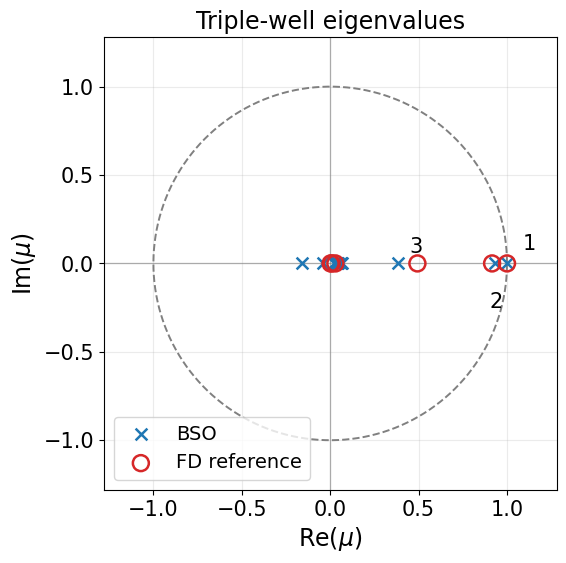


Figure caption:
Leading triple-well BSO multipliers at $T_{\mathrm{eff}}=3\tau=0.9$ compared with finer-grid finite-difference references mapped to the same horizon. Blue crosses show the 12 largest-$|\mu|$ BSO values and red circles the six references; one-to-one generator matching gives mean absolute error 0.0649.
Leading three generator eigenvalues (lambda):
  FD : +0.0000, -0.0979, -0.7851
  BSO: +0.0000, -0.0751, -1.0619
one-to-one generator eigenvalues vs FD reference:
  mode 0: ref +0.0000  matched +0.0000+0.0000j  |err|=3.059e-13
  mode 1: ref -0.0979  matched -0.0751+0.0000j  |err|=2.280e-02
  mode 2: ref -0.7851  matched -1.0619+0.0000j  |err|=2.768e-01
  mode 3: ref -3.9269  matched -3.9832+0.0000j  |err|=5.627e-02
  mode 4: ref -5.3446  matched -5.3374+0.0000j  |err|=7.205e-03
  mode 5: ref -6.7242  matched -6.6978+0.0000j  |err|=2.639e-02
head-6 MAE = 6.490e-02, max = 2.768e-01
r_eff = 49/49, cond(G) = 1.000e+00


In [ ]:
from scipy.optimize import linear_sum_assignment

mu = result.mu
lam = result.lam
order = np.argsort(-np.abs(mu))
mu_show = mu[order][:12]
ref = compute_triple_well_fd_reference_lambdas(n_eigs=6, N_ref=96 if QUICK else 128)
effective_horizon = int(cfg.get("projection_steps", 1)) * float(dataset["T"])
ref_mu = np.exp(ref * effective_horizon)
theta = np.linspace(0.0, 2.0 * np.pi, 512)

fig, ax = plt.subplots(
    1, 1, figsize=TW_SINGLE_FIGURE["figsize"], dpi=STYLE["dpi"], squeeze=True,
    sharex=False, sharey=False, layout=None, facecolor=STYLE["figure_face_color"],
)
fig.set_layout_engine(None)
ax.plot(np.cos(theta), np.sin(theta), color="gray",
        linewidth=STYLE["reference_line_width"], linestyle="--",
        marker=None, alpha=1.0, zorder=1)
ax.scatter(mu_show.real, mu_show.imag, color="tab:blue", marker="x",
           s=2.0 * STYLE["marker_size"] ** 2,
           linewidths=STYLE["marker_edge_width"], alpha=1.0,
           zorder=3, label="BSO")
ax.scatter(ref_mu.real, ref_mu.imag, facecolors="none", edgecolors="tab:red",
           marker="o", linewidths=STYLE["marker_edge_width"],
           s=2.0 * STYLE["marker_size"] ** 2, alpha=1.0,
           zorder=4, label=r"FD reference")
label_offsets = [(6, 6), (-2, -16), (5, 5)]
for idx, (val, offset) in enumerate(zip(mu_show[:3], label_offsets), start=1):
    ax.annotate(str(idx), (val.real, val.imag), textcoords="offset points",
                xytext=offset, fontsize=STYLE["annotation_size"],
                fontweight=STYLE["font_weight"], color=STYLE["text_color"],
                horizontalalignment="center", verticalalignment="center",
                annotation_clip=False, zorder=5)
ax.axhline(0.0, color="gray", linewidth=STYLE["reference_line_width"],
           linestyle="-", alpha=0.6, zorder=1)
ax.axvline(0.0, color="gray", linewidth=STYLE["reference_line_width"],
           linestyle="-", alpha=0.6, zorder=1)
ax.set_aspect("equal")
ax.set_xlabel(r"Re($\mu$)", fontsize=STYLE["axis_label_size"],
              fontweight=STYLE["font_weight"], labelpad=STYLE["axis_label_pad"],
              color=STYLE["text_color"])
ax.set_ylabel(r"Im($\mu$)", fontsize=STYLE["axis_label_size"],
              fontweight=STYLE["font_weight"], labelpad=STYLE["axis_label_pad"],
              color=STYLE["text_color"])
ax.set_title("Triple-well eigenvalues", fontsize=STYLE["panel_title_size"],
             fontweight=STYLE["title_weight"], pad=STYLE["panel_title_pad"],
             color=STYLE["text_color"])
style_axis(ax, grid_axis="both", grid_visible=True, minor_ticks=False)
ax.legend(
    loc="lower left", ncol=TW_SINGLE_FIGURE["legend_ncol"],
    frameon=STYLE["legend_frameon"], fancybox=STYLE["legend_fancybox"],
    framealpha=STYLE["legend_framealpha"], borderaxespad=STYLE["legend_borderaxespad"],
    borderpad=STYLE["legend_borderpad"], labelspacing=STYLE["legend_labelspacing"],
    handlelength=STYLE["legend_handlelength"], handleheight=STYLE["legend_handleheight"],
    handletextpad=STYLE["legend_handletextpad"], columnspacing=STYLE["legend_columnspacing"],
    fontsize=STYLE["legend_size"],
)
ax.set_xlim(-1.28, 1.28)
ax.set_ylim(-1.28, 1.28)
apply_physical_layout(fig, TW_SINGLE_FIGURE)
save_figure_pair(fig, FIGURES_DIR / 'triple_well' / 'tw_eigenvalues.pdf', dpi=STYLE["dpi"])
plt.show()
print_figure_caption(
    r"Leading triple-well BSO multipliers at $T_{\mathrm{eff}}=3\tau=0.9$ compared with finer-grid finite-difference references mapped to the same horizon. Blue crosses show the 12 largest-$|\mu|$ BSO values and red circles the six references; one-to-one generator matching gives mean absolute error 0.0649."
)

nonconstant = np.flatnonzero(np.abs(lam) > 1.0e-8)
cost = np.abs(ref[1:, None] - lam[nonconstant][None, :])
ref_rows, learned_cols = linear_sum_assignment(cost)
matched = {int(row + 1): int(nonconstant[col])
           for row, col in zip(ref_rows, learned_cols)}
leading_matched = [0, matched[1], matched[2]]
print("Leading three generator eigenvalues (lambda):")
print("  FD : " + ", ".join(f"{ref[n].real:+.4f}" for n in range(3)))
print("  BSO: " + ", ".join(f"{lam[j].real:+.4f}" for j in leading_matched))
errors = [abs(lam[int(np.argmin(np.abs(lam)))] - ref[0])]
print("one-to-one generator eigenvalues vs FD reference:")
print(f"  mode 0: ref {ref[0].real:+.4f}  matched {lam[0].real:+.4f}"
      f"{lam[0].imag:+.4f}j  |err|={errors[0]:.3e}")
for n in range(1, len(ref)):
    j = matched[n]
    err = abs(lam[j] - ref[n])
    errors.append(err)
    print(f"  mode {n}: ref {ref[n].real:+.4f}  matched {lam[j].real:+.4f}"
          f"{lam[j].imag:+.4f}j  |err|={err:.3e}")
print(f"head-{len(ref)} MAE = {np.mean(errors):.3e}, max = {np.max(errors):.3e}")
print(f"r_eff = {result.r_eff}/{result.psi.shape[0]}, cond(G) = {result.cond_G:.3e}")

## Eigenfunctions: the three wells

The leading BSO eigenfunctions encode the metastable decomposition:
$\varphi_1$ is the constant function, $\varphi_2$ separates the left and
right bottom wells, and $\varphi_3$ separates the upper well from the
bottom pair. For display, each nonconstant mode is propagated four times
with the jointly refined one-step operator and rescaled by its one-step
eigenvalue $\exp(\lambda\tau)$; invariant-mean centering and the known
reflection parity remove constant and symmetry-breaking contamination.

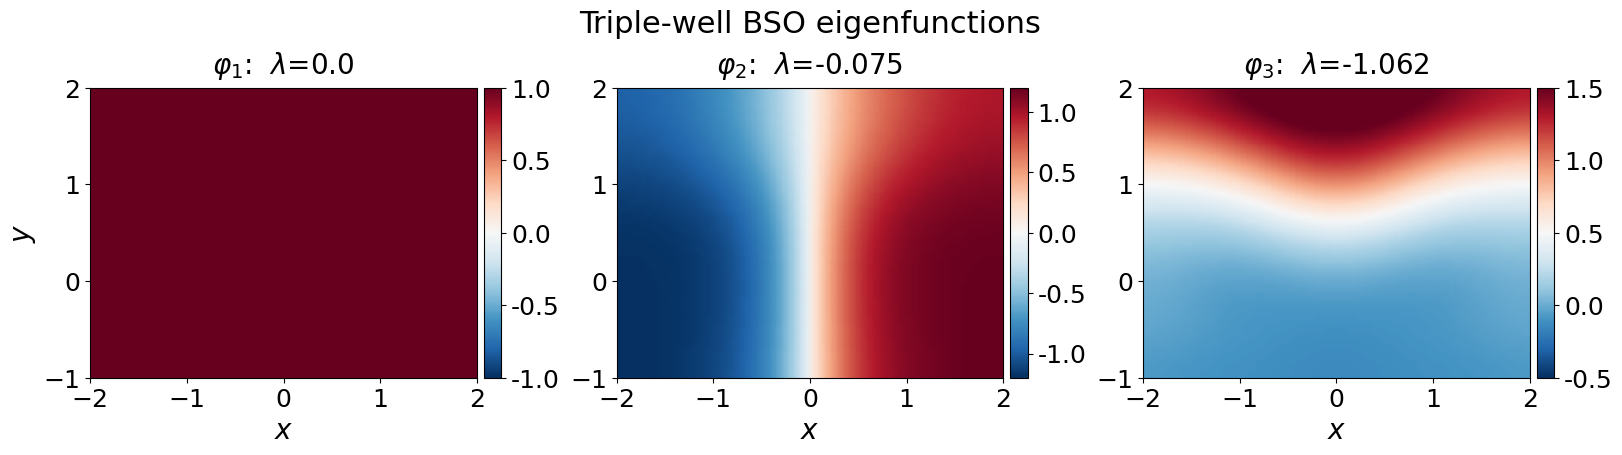


Figure caption:
Leading triple-well BSO eigenfunctions on the triple-well state-space domain. The stationary mode is followed by an odd left--right partition and an even upper-versus-lower partition of the three wells; panels use independent display scales and visualization postprocessing, including symmetry constraints and smoothing.


In [ ]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.ticker as mticker
from scipy.ndimage import gaussian_filter
import torch
from edmd_bso_method import apply_operator, device
from kbe_observation_data import tw_potential

# ---- display settings for the figure layout ----
PHI2_CLIM = (-1.2, 1.2)   # phi_2 colorbar limits (min, max)
PHI2_SIGMA = 7.0          # phi_2 smoothing strength
PHI2_GAMMA = 0.75         # phi_2 center dilution: smaller -> thinner white band
PHI3_CLIM = (-0.5, 1.5)   # phi_3 colorbar limits (min, max)
PHI3_SIGMA = 7.0          # phi_3 smoothing strength

N = dataset["meta"]["params"]["N"]
X, Y = dataset["meta"]["X"], dataset["meta"]["Y"]
V = tw_potential(X, Y)
rho = np.exp(-(V - V.min()) / dataset["meta"]["params"]["D"])
rho = rho / rho.sum()
order = np.argsort(-result.lam.real)
grid_t = torch.as_tensor(result.grid, dtype=torch.float32, device=device)
display_operator = (result.operator_joint
                    if result.operator_joint is not None else result.operator)

M_STEPS = 4
anchors = [None, (1.0, 0.0), (0.0, 5.0 / 3.0)]
parity = [None, -1.0, 1.0]
sigmas = [None, PHI2_SIGMA, PHI3_SIGMA]
clims = [(-1.0, 1.0), PHI2_CLIM, PHI3_CLIM]
fig, axes = plt.subplots(
    1, 3, figsize=TW_GRID_FIGURE["figsize"], dpi=STYLE["dpi"], squeeze=True,
    sharex=False, sharey=False, layout=None, facecolor=STYLE["figure_face_color"],
)
fig.set_layout_engine(None)
for k, ax in enumerate(axes):
    j = order[k]
    ef = result.eigenfunctions[j].real.reshape(N, N)
    if k == 0:
        ef = np.full_like(ef, np.clip(np.nanmedian(ef), -1.0, 1.0))
    else:
        one_step_mu_j = float(np.exp(result.lam[j].real * result.T))
        ef = ef - np.sum(rho * ef)
        t = torch.as_tensor(ef.reshape(1, -1), dtype=torch.float32, device=device)
        with torch.no_grad():
            for _ in range(M_STEPS):
                t = apply_operator(display_operator, t, grid_t, result.kind)
        ef = t.squeeze(0).cpu().numpy().astype(np.float64).reshape(N, N)
        ef = ef / (one_step_mu_j ** M_STEPS + 1e-300)
        ef = ef - np.sum(rho * ef)
        ef = 0.5 * (ef + parity[k] * ef[::-1, :])
        cx, cy = anchors[k]
        ii = np.unravel_index(np.argmin((X - cx) ** 2 + (Y - cy) ** 2), X.shape)
        if ef[ii] < 0:
            ef = -ef
        ef = gaussian_filter(ef, sigma=sigmas[k])
        if k == 1 and PHI2_GAMMA != 1.0:
            lim = PHI2_CLIM[1]
            ef = np.sign(ef) * (np.abs(ef) / lim) ** PHI2_GAMMA * lim
    im = ax.pcolormesh(X, Y, ef, cmap="RdBu_r", vmin=clims[k][0],
                       vmax=clims[k][1], shading="gouraud")
    divider = make_axes_locatable(ax)
    cax = divider.append_axes(
        "right", size=TW_GRID_FIGURE["colorbar_size_percent"],
        pad=TW_GRID_FIGURE["colorbar_pad_in"],
    )
    cbar = fig.colorbar(im, cax=cax)
    cbar.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
    cbar.ax.tick_params(
        axis="y", which="major", direction="out",
        length=STYLE["major_tick_length"], width=STYLE["major_tick_width"],
        pad=STYLE["tick_label_pad"], labelsize=STYLE["colorbar_tick_size"],
        colors=STYLE["text_color"], left=False, right=True,
        labelleft=False, labelright=True,
    )
    cbar.outline.set_linewidth(STYLE["axes_line_width"])
    cbar.outline.set_edgecolor(STYLE["axes_edge_color"])
    lambda_label = "0.0" if k == 0 else f"{result.lam[order[k]].real:+.3f}"
    ax.set_title(rf"$\varphi_{{{k + 1}}}$:  $\lambda$={lambda_label}",
                 fontsize=STYLE["panel_title_size"], fontweight=STYLE["title_weight"],
                 pad=STYLE["panel_title_pad"], color=STYLE["text_color"])
    ax.set_xlabel("$x$", fontsize=STYLE["axis_label_size"],
                  fontweight=STYLE["font_weight"], labelpad=STYLE["axis_label_pad"],
                  color=STYLE["text_color"])
    if k == 0:
        ax.set_ylabel("$y$", fontsize=STYLE["axis_label_size"],
                      fontweight=STYLE["font_weight"], labelpad=STYLE["axis_label_pad"],
                      color=STYLE["text_color"])
    style_axis(ax, grid_axis="both", grid_visible=False, minor_ticks=False)
    ax.set_aspect("equal")
apply_physical_layout(fig, TW_GRID_FIGURE)
fig.suptitle(
    "Triple-well BSO eigenfunctions", fontsize=STYLE["suptitle_size"],
    fontweight=STYLE["title_weight"], color=STYLE["text_color"], x=0.5,
    y=y_from_top(fig, TW_GRID_FIGURE["suptitle_top_in"]),
    horizontalalignment="center", verticalalignment="top", zorder=100,
)
save_figure_pair(fig, FIGURES_DIR / 'triple_well' / 'tw_eigenfunctions.pdf', dpi=STYLE["dpi"])
plt.show()
print_figure_caption(
    "Leading triple-well BSO eigenfunctions on the triple-well state-space domain. The stationary mode is followed by an odd left--right partition and an even upper-versus-lower partition of the three wells; panels use independent display scales and visualization postprocessing, including symmetry constraints and smoothing."
)